In [1]:
import copy
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu



=== Part A: Gradient Descent Comparison (True w=3.5, b=1.2) ===
              Method  Final w  Final b  Final MSE  Total Updates  Time (s)
    Batch GD (B=200)   3.4870   1.2220     0.2442            100    0.0030
Mini-Batch GD (B=32)   3.5583   1.2334     0.2404            700    0.0204
 Stochastic GD (B=1)   3.5842   1.1723     0.2465          20000    0.2876


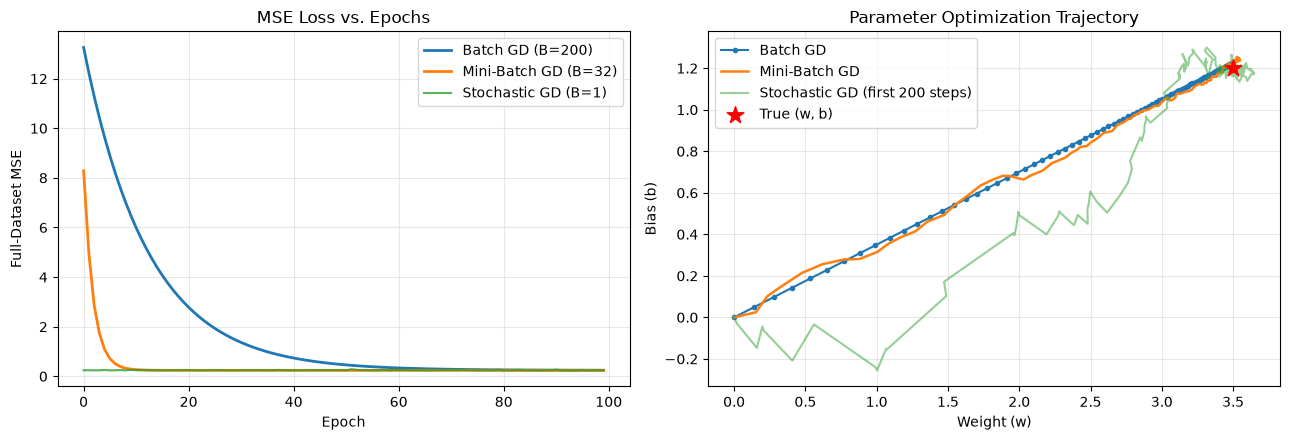

In [2]:

set_seed(42)
N = 200
X = np.random.randn(N, 1)
X = (X - X.mean()) / X.std()  # Standardize for controlled convergence
true_w, true_b = 3.5, 1.2
y = true_w * X + true_b + 0.5 * np.random.randn(N, 1)

def compute_mse(X_data, y_data, w, b):
    preds = X_data * w + b
    return np.mean((preds - y_data) ** 2)

def run_gradient_descent(X_data, y_data, batch_size, lr=0.02, epochs=100, seed=42):
    rng = np.random.default_rng(seed)
    w, b = 0.0, 0.0
    n_samples = len(X_data)

    epoch_losses = []
    step_losses = []
    w_history, b_history = [w], [b]

    start_time = time.time()
    for _ in range(epochs):
        indices = rng.permutation(n_samples)
        X_shuf, y_shuf = X_data[indices], y_data[indices]

        for start in range(0, n_samples, batch_size):
            end = start + batch_size
            xb = X_shuf[start:end]
            yb = y_shuf[start:end]

            preds = xb * w + b
            error = preds - yb
            dw = (2.0 / len(xb)) * np.sum(xb * error)
            db = (2.0 / len(xb)) * np.sum(error)

            w -= lr * dw
            b -= lr * db

            step_losses.append(compute_mse(X_data, y_data, w, b))
            w_history.append(w)
            b_history.append(b)

        epoch_losses.append(compute_mse(X_data, y_data, w, b))

    elapsed = time.time() - start_time
    return {
        "w": w, "b": b,
        "epoch_losses": epoch_losses,
        "step_losses": step_losses,
        "w_history": w_history,
        "b_history": b_history,
        "time_sec": elapsed,
        "total_updates": len(step_losses),
    }


bgd_res  = run_gradient_descent(X, y, batch_size=N,  lr=0.02, epochs=100)
sgd_res  = run_gradient_descent(X, y, batch_size=1,  lr=0.02, epochs=100)
mbgd_res = run_gradient_descent(X, y, batch_size=32, lr=0.02, epochs=100)

gd_summary = pd.DataFrame([
    {"Method": "Batch GD (B=200)",     "Final w": round(bgd_res["w"], 4),  "Final b": round(bgd_res["b"], 4),  "Final MSE": round(bgd_res["epoch_losses"][-1], 4),  "Total Updates": bgd_res["total_updates"],  "Time (s)": round(bgd_res["time_sec"], 4)},
    {"Method": "Mini-Batch GD (B=32)", "Final w": round(mbgd_res["w"], 4), "Final b": round(mbgd_res["b"], 4), "Final MSE": round(mbgd_res["epoch_losses"][-1], 4), "Total Updates": mbgd_res["total_updates"], "Time (s)": round(mbgd_res["time_sec"], 4)},
    {"Method": "Stochastic GD (B=1)",  "Final w": round(sgd_res["w"], 4),  "Final b": round(sgd_res["b"], 4),  "Final MSE": round(sgd_res["epoch_losses"][-1], 4),  "Total Updates": sgd_res["total_updates"],  "Time (s)": round(sgd_res["time_sec"], 4)},
])
print("\n=== Part A: Gradient Descent Comparison (True w=3.5, b=1.2) ===")
print(gd_summary.to_string(index=False))


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))


axes[0].plot(bgd_res["epoch_losses"],  label="Batch GD (B=200)", linewidth=2)
axes[0].plot(mbgd_res["epoch_losses"], label="Mini-Batch GD (B=32)", linewidth=2)
axes[0].plot(sgd_res["epoch_losses"],  label="Stochastic GD (B=1)", alpha=0.8)
axes[0].set_title("MSE Loss vs. Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Full-Dataset MSE")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(bgd_res["w_history"],  bgd_res["b_history"],  "o-", markersize=3, label="Batch GD")
axes[1].plot(mbgd_res["w_history"][:200], mbgd_res["b_history"][:200], "-", linewidth=1.8, label="Mini-Batch GD")
axes[1].plot(sgd_res["w_history"][:200],  sgd_res["b_history"][:200],  "-", alpha=0.5, label="Stochastic GD (first 200 steps)")
axes[1].scatter([true_w], [true_b], color="red", marker="*", s=160, zorder=5, label="True (w, b)")
axes[1].set_title("Parameter Optimization Trajectory")
axes[1].set_xlabel("Weight (w)")
axes[1].set_ylabel("Bias (b)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [3]:
FMNIST_MEAN = (0.2860,)
FMNIST_STD  = (0.3530,)

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(FMNIST_MEAN, FMNIST_STD),
])

aug_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=10, translate=(0.08, 0.08)),
    transforms.ToTensor(),
    transforms.Normalize(FMNIST_MEAN, FMNIST_STD),
])

full_train_plain = datasets.FashionMNIST(root="./data", train=True,  download=True, transform=eval_transform)
full_train_aug   = datasets.FashionMNIST(root="./data", train=True,  download=True, transform=aug_transform)
full_test        = datasets.FashionMNIST(root="./data", train=False, download=True, transform=eval_transform)

rng = np.random.default_rng(42)
perm_train = rng.permutation(len(full_train_plain))
perm_test  = rng.permutation(len(full_test))

train_idx_5k = perm_train[:5000]
val_idx_1k   = perm_train[5000:6000]
test_idx_1k  = perm_test[:1000]

train_idx_small = perm_train[:1500]

def make_loader(dataset, indices, batch_size=64, shuffle=False, seed=42):
    g = torch.Generator()
    g.manual_seed(seed)
    return DataLoader(Subset(dataset, indices), batch_size=batch_size, shuffle=shuffle, generator=g)

val_loader  = make_loader(full_train_plain, val_idx_1k,  batch_size=128, shuffle=False)
test_loader = make_loader(full_test,        test_idx_1k, batch_size=128, shuffle=False)

def evaluate_model(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, 100.0 * correct / total

def train_model(
    model, train_loader, val_loader, optimizer, criterion,
    epochs=15, scheduler=None, early_stopping_patience=None, track_grad_norm=False
):
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "lr": [], "first_layer_grad": []}
    best_val_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())
    patience_counter = 0

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        grad_norms = []

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()

            if track_grad_norm:
                first_param = next(model.parameters())
                if first_param.grad is not None:
                    grad_norms.append(first_param.grad.norm().item())

            optimizer.step()
            running_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc  = 100.0 * correct / total
        val_loss, val_acc = evaluate_model(model, val_loader, criterion)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["lr"].append(optimizer.param_groups[0]["lr"])
        if track_grad_norm:
            history["first_layer_grad"].append(float(np.mean(grad_norms)))

        if scheduler is not None:
            scheduler.step()

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if early_stopping_patience is not None and patience_counter >= early_stopping_patience:
            print(f"Early stopping triggered at epoch {epoch} (best val loss: {best_val_loss:.4f})")
            break

    if early_stopping_patience is not None:
        model.load_state_dict(best_weights)

    return history

100.0%
100.0%
100.0%
100.0%



=== Part B: Optimizer & LR Schedule Comparison (Fashion-MNIST 5k Subset) ===
   Optimizer   LR Mode  Final Train Acc (%)  Best Val Acc (%)  Final Val Loss  Test Acc (%)
SGD+Momentum  Constant                92.78              84.6          0.6204          82.0
SGD+Momentum Scheduled                97.84              85.9          0.5343          85.2
SGD+Nesterov  Constant                94.00              84.2          0.6369          82.1
SGD+Nesterov Scheduled                99.08              85.7          0.5762          84.7
     RMSprop  Constant                95.72              84.8          1.4535          78.1
     RMSprop Scheduled                97.06              86.1          0.4497          85.0
        Adam  Constant                96.00              85.3          0.5700          84.2
        Adam Scheduled                96.94              86.1          0.4397          86.1


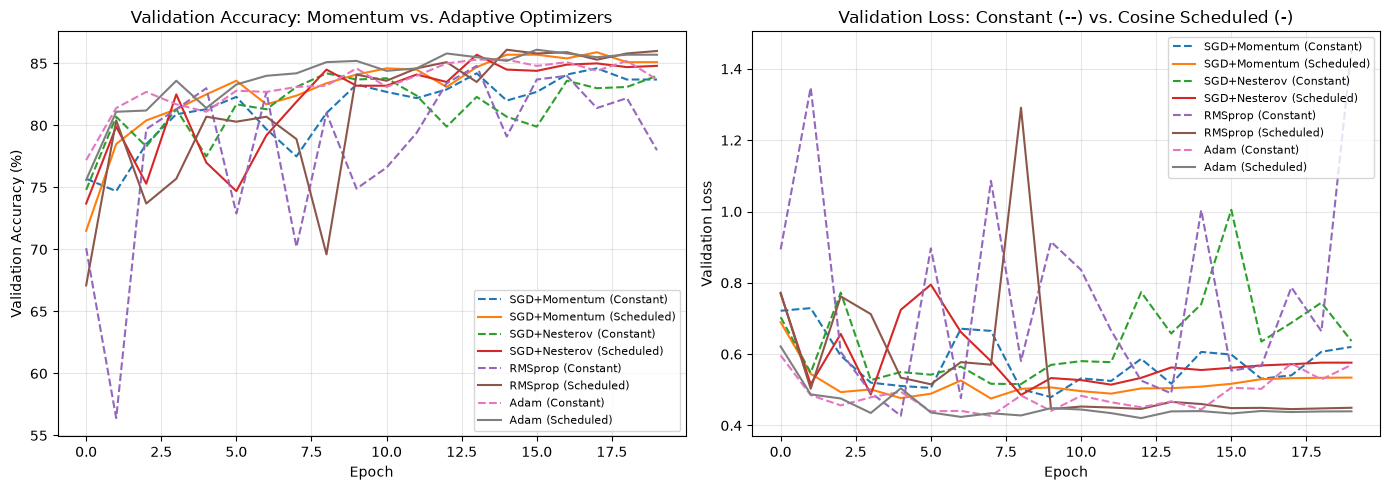

In [ ]:
class StandardMLP(nn.Module):
    def __init__(self, hidden_dims=(256, 128), dropout_p=0.0):
        super().__init__()
        layers = [nn.Flatten()]
        in_dim = 28 * 28
        for h in hidden_dims:
            layers.append(nn.Linear(in_dim, h))
            layers.append(nn.ReLU())
            if dropout_p > 0:
                layers.append(nn.Dropout(dropout_p))
            in_dim = h
        layers.append(nn.Linear(in_dim, 10))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

set_seed(42)
base_mlp = StandardMLP(hidden_dims=(256, 128), dropout_p=0.0).to(device)
base_mlp_weights = copy.deepcopy(base_mlp.state_dict())
criterion = nn.CrossEntropyLoss()

EPOCHS_OPT = 20
train_loader_5k = make_loader(full_train_plain, train_idx_5k, batch_size=64, shuffle=True, seed=42)

optimizer_configs = [
    ("SGD+Momentum", "Constant",  lambda p: optim.SGD(p, lr=0.05, momentum=0.9),                   False),
    ("SGD+Momentum", "Scheduled", lambda p: optim.SGD(p, lr=0.05, momentum=0.9),                   True),
    ("SGD+Nesterov", "Constant",  lambda p: optim.SGD(p, lr=0.05, momentum=0.9, nesterov=True),    False),
    ("SGD+Nesterov", "Scheduled", lambda p: optim.SGD(p, lr=0.05, momentum=0.9, nesterov=True),    True),
    ("RMSprop",      "Constant",  lambda p: optim.RMSprop(p, lr=0.001, alpha=0.99),                False),
    ("RMSprop",      "Scheduled", lambda p: optim.RMSprop(p, lr=0.001, alpha=0.99),                True),
    ("Adam",         "Constant",  lambda p: optim.Adam(p, lr=0.001),                               False),
    ("Adam",         "Scheduled", lambda p: optim.Adam(p, lr=0.001),                               True),
]

opt_histories = {}
opt_rows = []

for opt_name, lr_mode, opt_fn, use_sched in optimizer_configs:
    set_seed(42)
    model = StandardMLP(hidden_dims=(256, 128), dropout_p=0.0).to(device)
    model.load_state_dict(copy.deepcopy(base_mlp_weights))

    optimizer = opt_fn(model.parameters())
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_OPT, eta_min=1e-5) if use_sched else None

    hist = train_model(model, train_loader_5k, val_loader, optimizer, criterion, epochs=EPOCHS_OPT, scheduler=scheduler)
    test_loss, test_acc = evaluate_model(model, test_loader, criterion)

    key = f"{opt_name} ({lr_mode})"
    opt_histories[key] = hist
    opt_rows.append({
        "Optimizer": opt_name,
        "LR Mode": lr_mode,
        "Final Train Acc (%)": round(hist["train_acc"][-1], 2),
        "Best Val Acc (%)":    round(max(hist["val_acc"]), 2),
        "Final Val Loss":      round(hist["val_loss"][-1], 4),
        "Test Acc (%)":        round(test_acc, 2),
    })

opt_df = pd.DataFrame(opt_rows)
print("\n=== Part B: Optimizer & LR Schedule Comparison (Fashion-MNIST 5k Subset) ===")
print(opt_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for key, hist in opt_histories.items():
    style = "--" if "Constant" in key else "-"
    axes[0].plot(hist["val_acc"],  linestyle=style, label=key)
    axes[1].plot(hist["val_loss"], linestyle=style, label=key)

axes[0].set_title("Validation Accuracy: Momentum vs. Adaptive Optimizers")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation Accuracy (%)")
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)

axes[1].set_title("Validation Loss: Constant (--) vs. Cosine Scheduled (-)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation Loss")
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Early stopping triggered at epoch 22 (best val loss: 0.5918)

=== Part C: Overfitting & Regularization Evaluation ===
            Configuration  Epochs Run  Train Acc (%)  Val Acc (%)  Train-Val Gap (%)  Min Val Loss  Test Acc (%)
        Baseline (No Reg)          35          98.73         81.6              17.13        0.5398          81.0
          Dropout (p=0.4)          35          94.33         81.1              13.23        0.5164          81.9
         L2 Reg (wd=1e-3)          35          97.53         80.6              16.93        0.5177          81.9
        Data Augmentation          35          83.20         81.1               2.10        0.5441          78.2
Combined + Early Stopping          22          74.53         76.5              -1.97        0.5918          74.3


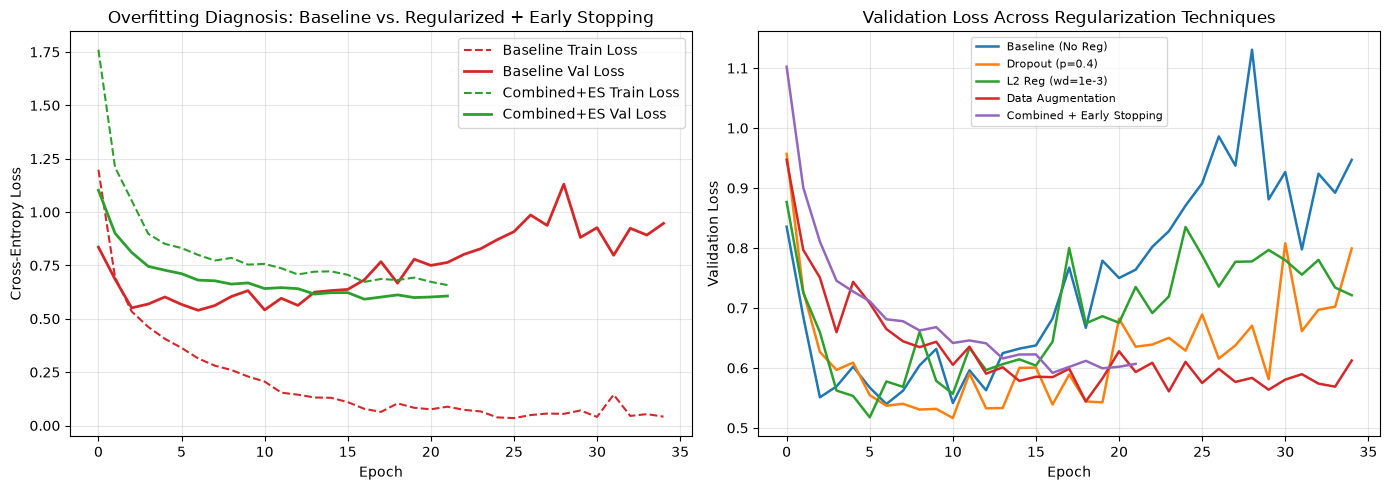

In [ ]:
set_seed(42)
overfit_base = StandardMLP(hidden_dims=(512, 256, 128), dropout_p=0.0).to(device)
overfit_base_weights = copy.deepcopy(overfit_base.state_dict())

train_loader_small_plain = make_loader(full_train_plain, train_idx_small, batch_size=64, shuffle=True, seed=42)
train_loader_small_aug   = make_loader(full_train_aug,   train_idx_small, batch_size=64, shuffle=True, seed=42)

EPOCHS_REG = 35
reg_experiments = [
    {"name": "Baseline (No Reg)",        "dropout": 0.0, "wd": 0.0,   "aug": False, "patience": None},
    {"name": "Dropout (p=0.4)",          "dropout": 0.4, "wd": 0.0,   "aug": False, "patience": None},
    {"name": "L2 Reg (wd=1e-3)",         "dropout": 0.0, "wd": 1e-3,  "aug": False, "patience": None},
    {"name": "Data Augmentation",        "dropout": 0.0, "wd": 0.0,   "aug": True,  "patience": None},
    {"name": "Combined + Early Stopping","dropout": 0.3, "wd": 1e-3,  "aug": True,  "patience": 5},
]

reg_histories = {}
reg_rows = []

for cfg in reg_experiments:
    set_seed(42)
    model = StandardMLP(hidden_dims=(512, 256, 128), dropout_p=cfg["dropout"]).to(device)

    src_linears = [m for m in overfit_base.modules() if isinstance(m, nn.Linear)]
    dst_linears = [m for m in model.modules() if isinstance(m, nn.Linear)]
    for s, d in zip(src_linears, dst_linears):
        d.load_state_dict(copy.deepcopy(s.state_dict()))

    optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=cfg["wd"])
    loader = train_loader_small_aug if cfg["aug"] else train_loader_small_plain

    hist = train_model(
        model, loader, val_loader, optimizer, criterion,
        epochs=EPOCHS_REG, early_stopping_patience=cfg["patience"]
    )
    test_loss, test_acc = evaluate_model(model, test_loader, criterion)

    reg_histories[cfg["name"]] = hist
    final_train_acc = hist["train_acc"][-1]
    final_val_acc   = hist["val_acc"][-1]
    reg_rows.append({
        "Configuration":     cfg["name"],
        "Epochs Run":        len(hist["train_loss"]),
        "Train Acc (%)":     round(final_train_acc, 2),
        "Val Acc (%)":       round(final_val_acc, 2),
        "Train-Val Gap (%)": round(final_train_acc - final_val_acc, 2),
        "Min Val Loss":      round(min(hist["val_loss"]), 4),
        "Test Acc (%)":      round(test_acc, 2),
    })

reg_df = pd.DataFrame(reg_rows)
print("\n=== Part C: Overfitting & Regularization Evaluation ===")
print(reg_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Train vs. Val Loss for Baseline (proving overfitting) vs. Combined + Early Stopping
axes[0].plot(reg_histories["Baseline (No Reg)"]["train_loss"], label="Baseline Train Loss", linestyle="--", color="tab:red")
axes[0].plot(reg_histories["Baseline (No Reg)"]["val_loss"],   label="Baseline Val Loss",   linewidth=2,   color="tab:red")
axes[0].plot(reg_histories["Combined + Early Stopping"]["train_loss"], label="Combined+ES Train Loss", linestyle="--", color="tab:green")
axes[0].plot(reg_histories["Combined + Early Stopping"]["val_loss"],   label="Combined+ES Val Loss",   linewidth=2,   color="tab:green")
axes[0].set_title("Overfitting Diagnosis: Baseline vs. Regularized + Early Stopping")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

for name, hist in reg_histories.items():
    axes[1].plot(hist["val_loss"], label=name, linewidth=1.8)
axes[1].set_title("Validation Loss Across Regularization Techniques")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation Loss")
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Parameter Count Check -> Plain MLP: 867,082 | Residual MLP: 867,082

=== Part D: Plain vs. Residual Deep MLP (Controlled Conditions) ===
                 Architecture  Parameters  Final Train Loss  Best Val Acc (%)  Test Acc (%)  Avg Layer-1 Grad Norm
   Plain Deep MLP (12 layers)      867082            0.6747              74.1          71.8                 0.5315
Residual Deep MLP (12 layers)      867082            0.2342              83.5          83.0                 0.6993


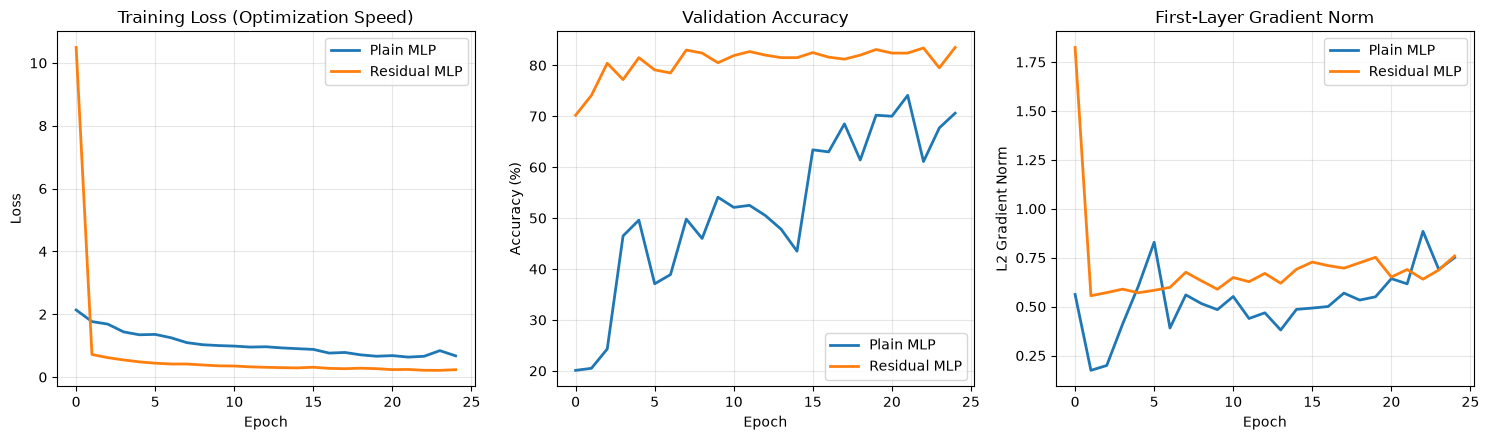

In [6]:
class MLPBlock(nn.Module):
    def __init__(self, dim, residual=False):
        super().__init__()
        self.residual = residual
        self.fc1 = nn.Linear(dim, dim)
        self.ln1 = nn.LayerNorm(dim)
        self.fc2 = nn.Linear(dim, dim)
        self.ln2 = nn.LayerNorm(dim)
        self.relu = nn.ReLU()

    def forward(self, x):
        out = self.relu(self.ln1(self.fc1(x)))
        out = self.ln2(self.fc2(out))
        if self.residual:
            out = out + x  # Residual skip connection
        return self.relu(out)

class DeepMLP(nn.Module):
    def __init__(self, hidden_dim=256, num_blocks=5, residual=False):
        super().__init__()
        self.flatten = nn.Flatten()
        self.input_proj = nn.Sequential(
            nn.Linear(28 * 28, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
        )
        self.blocks = nn.Sequential(*[MLPBlock(hidden_dim, residual=residual) for _ in range(num_blocks)])
        self.head = nn.Linear(hidden_dim, 10)

    def forward(self, x):
        h = self.input_proj(self.flatten(x))
        h = self.blocks(h)
        return self.head(h)

set_seed(42)
plain_deep_mlp = DeepMLP(hidden_dim=256, num_blocks=5, residual=False).to(device)
res_deep_mlp   = DeepMLP(hidden_dim=256, num_blocks=5, residual=True).to(device)
res_deep_mlp.load_state_dict(copy.deepcopy(plain_deep_mlp.state_dict()))

plain_params = sum(p.numel() for p in plain_deep_mlp.parameters())
res_params   = sum(p.numel() for p in res_deep_mlp.parameters())
print(f"\nParameter Count Check -> Plain MLP: {plain_params:,} | Residual MLP: {res_params:,}")

EPOCHS_RES = 25
opt_plain = optim.SGD(plain_deep_mlp.parameters(), lr=0.05, momentum=0.9)
opt_res   = optim.SGD(res_deep_mlp.parameters(),   lr=0.05, momentum=0.9)

set_seed(42)
hist_plain = train_model(
    plain_deep_mlp, train_loader_5k, val_loader, opt_plain, criterion,
    epochs=EPOCHS_RES, track_grad_norm=True
)
_, test_acc_plain = evaluate_model(plain_deep_mlp, test_loader, criterion)

set_seed(42)
hist_res = train_model(
    res_deep_mlp, train_loader_5k, val_loader, opt_res, criterion,
    epochs=EPOCHS_RES, track_grad_norm=True
)
_, test_acc_res = evaluate_model(res_deep_mlp, test_loader, criterion)

arch_df = pd.DataFrame([
    {
        "Architecture": "Plain Deep MLP (12 layers)",
        "Parameters": plain_params,
        "Final Train Loss": round(hist_plain["train_loss"][-1], 4),
        "Best Val Acc (%)": round(max(hist_plain["val_acc"]), 2),
        "Test Acc (%)": round(test_acc_plain, 2),
        "Avg Layer-1 Grad Norm": round(float(np.mean(hist_plain["first_layer_grad"])), 4),
    },
    {
        "Architecture": "Residual Deep MLP (12 layers)",
        "Parameters": res_params,
        "Final Train Loss": round(hist_res["train_loss"][-1], 4),
        "Best Val Acc (%)": round(max(hist_res["val_acc"]), 2),
        "Test Acc (%)": round(test_acc_res, 2),
        "Avg Layer-1 Grad Norm": round(float(np.mean(hist_res["first_layer_grad"])), 4),
    },
])
print("\n=== Part D: Plain vs. Residual Deep MLP (Controlled Conditions) ===")
print(arch_df.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].plot(hist_plain["train_loss"], label="Plain MLP", linewidth=2)
axes[0].plot(hist_res["train_loss"],   label="Residual MLP", linewidth=2)
axes[0].set_title("Training Loss (Optimization Speed)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(hist_plain["val_acc"], label="Plain MLP", linewidth=2)
axes[1].plot(hist_res["val_acc"],   label="Residual MLP", linewidth=2)
axes[1].set_title("Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].plot(hist_plain["first_layer_grad"], label="Plain MLP", linewidth=2)
axes[2].plot(hist_res["first_layer_grad"],   label="Residual MLP", linewidth=2)
axes[2].set_title("First-Layer Gradient Norm")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("L2 Gradient Norm")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()